## 标准位置编码和旋转位置编码的实现

In [1]:
import torch

def precompute_freqs_cis(dim, seqlen, theta = 10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(seqlen)   #顺序位置，0 ~ seqlen - 1
    freqs = torch.outer(t, freqs).float() 
    return freqs

embedding_dim = 8
sequence_length = 5

# 标记嵌入，全为1
token_embedding = torch.ones((sequence_length, embedding_dim))

freqs = precompute_freqs_cis(embedding_dim, sequence_length)

# 标准位置编码
pe = torch.zeros(sequence_length, embedding_dim)
pe[:, 0::2] = torch.sin(freqs)
pe[:, 1::2] = torch.cos(freqs)

# 标记嵌入 + 位置嵌入
pe_out = token_embedding + pe
print(pe_out)

# 旋转位置编码
freqs_cis = torch.polar(torch.ones_like(freqs), freqs)
token_embedding_cis = torch.view_as_complex(token_embedding.reshape(sequence_length,-1,2))
rope_out = torch.view_as_real(token_embedding_cis * freqs_cis).flatten(1)
print(rope_out)

tensor([[1.0000, 2.0000, 1.0000, 2.0000, 1.0000, 2.0000, 1.0000, 2.0000],
        [1.8415, 1.5403, 1.0998, 1.9950, 1.0100, 1.9999, 1.0010, 2.0000],
        [1.9093, 0.5839, 1.1987, 1.9801, 1.0200, 1.9998, 1.0020, 2.0000],
        [1.1411, 0.0100, 1.2955, 1.9553, 1.0300, 1.9996, 1.0030, 2.0000],
        [0.2432, 0.3464, 1.3894, 1.9211, 1.0400, 1.9992, 1.0040, 2.0000]])
tensor([[ 1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000,  1.0000],
        [-0.3012,  1.3818,  0.8952,  1.0948,  0.9900,  1.0099,  0.9990,  1.0010],
        [-1.3254,  0.4932,  0.7814,  1.1787,  0.9798,  1.0198,  0.9980,  1.0020],
        [-1.1311, -0.8489,  0.6598,  1.2509,  0.9696,  1.0295,  0.9970,  1.0030],
        [ 0.1032, -1.4104,  0.5316,  1.3105,  0.9592,  1.0392,  0.9960,  1.0040]])


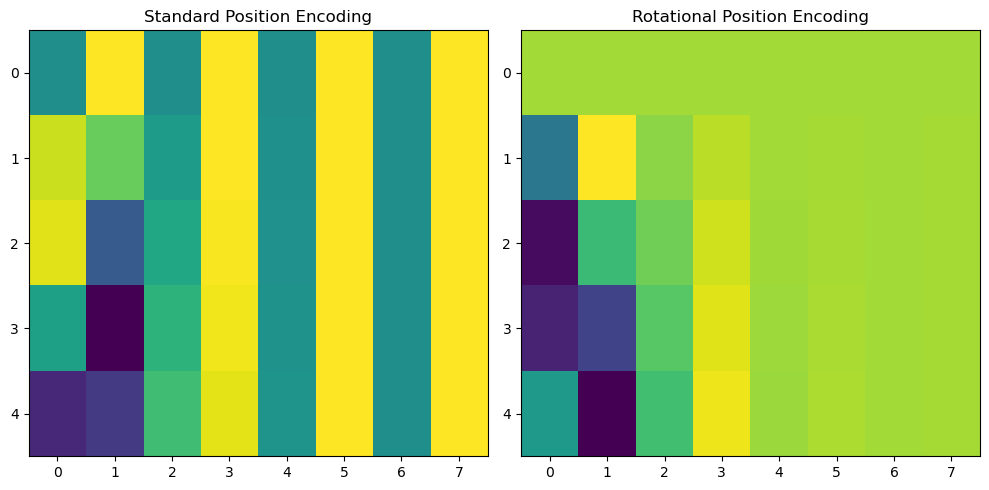

In [2]:
import matplotlib.pyplot as plt

# 假设你已经有了两个位置编码张量：standard_pos_encoding和rotational_pos_encoding
# 它们都是shape为(length, dimensions)的二维张量

plt.figure(figsize=(10, 5))

# 绘制标准位置编码
plt.subplot(1, 2, 1)
plt.imshow(pe_out.numpy(), aspect='auto')
plt.title('Standard Position Encoding')

# 绘制旋转位置编码
plt.subplot(1, 2, 2)
plt.imshow(rope_out.numpy(), aspect='auto')
plt.title('Rotational Position Encoding')

plt.tight_layout()
plt.show()

In [3]:
torch.set_printoptions(precision=4,sci_mode=False, linewidth=120)
freqs

tensor([[    0.0000,     0.0000,     0.0000,     0.0000],
        [    1.0000,     0.1000,     0.0100,     0.0010],
        [    2.0000,     0.2000,     0.0200,     0.0020],
        [    3.0000,     0.3000,     0.0300,     0.0030],
        [    4.0000,     0.4000,     0.0400,     0.0040]])

In [4]:
freqs_cis

tensor([[ 1.0000+0.0000j,  1.0000+0.0000j,  1.0000+0.0000j,  1.0000+0.0000j],
        [ 0.5403+0.8415j,  0.9950+0.0998j,  0.9999+0.0100j,  1.0000+0.0010j],
        [-0.4161+0.9093j,  0.9801+0.1987j,  0.9998+0.0200j,  1.0000+0.0020j],
        [-0.9900+0.1411j,  0.9553+0.2955j,  0.9996+0.0300j,  1.0000+0.0030j],
        [-0.6536-0.7568j,  0.9211+0.3894j,  0.9992+0.0400j,  1.0000+0.0040j]])

In [5]:
token_embedding_cis

tensor([[1.+1.j, 1.+1.j, 1.+1.j, 1.+1.j],
        [1.+1.j, 1.+1.j, 1.+1.j, 1.+1.j],
        [1.+1.j, 1.+1.j, 1.+1.j, 1.+1.j],
        [1.+1.j, 1.+1.j, 1.+1.j, 1.+1.j],
        [1.+1.j, 1.+1.j, 1.+1.j, 1.+1.j]])

In [6]:
token_embedding_cis * freqs_cis

tensor([[ 1.0000+1.0000j,  1.0000+1.0000j,  1.0000+1.0000j,  1.0000+1.0000j],
        [-0.3012+1.3818j,  0.8952+1.0948j,  0.9900+1.0099j,  0.9990+1.0010j],
        [-1.3254+0.4932j,  0.7814+1.1787j,  0.9798+1.0198j,  0.9980+1.0020j],
        [-1.1311-0.8489j,  0.6598+1.2509j,  0.9696+1.0295j,  0.9970+1.0030j],
        [ 0.1032-1.4104j,  0.5316+1.3105j,  0.9592+1.0392j,  0.9960+1.0040j]])

## precompute_freqs_cis函数解析

In [7]:
dim = 6
end = 12
theta = 10000.0

freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
t = torch.arange(end, device=freqs.device)  # type: ignore
freqs = torch.outer(t, freqs).float()  # type: ignore
freqs_cis = torch.polar(torch.ones_like(freqs), freqs)  # complex64

In [14]:
torch.arange(0, dim, 2)

tensor([0, 2, 4])

In [15]:
torch.arange(0, dim, 2)[: (dim // 2)]

tensor([0, 2, 4])

In [16]:
torch.arange(0, dim, 2)[: (dim // 2)].float() / dim

tensor([0.0000, 0.3333, 0.6667])

In [17]:
t

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [19]:
freqs

tensor([[    0.0000,     0.0000,     0.0000],
        [    1.0000,     0.0464,     0.0022],
        [    2.0000,     0.0928,     0.0043],
        [    3.0000,     0.1392,     0.0065],
        [    4.0000,     0.1857,     0.0086],
        [    5.0000,     0.2321,     0.0108],
        [    6.0000,     0.2785,     0.0129],
        [    7.0000,     0.3249,     0.0151],
        [    8.0000,     0.3713,     0.0172],
        [    9.0000,     0.4177,     0.0194],
        [   10.0000,     0.4642,     0.0215],
        [   11.0000,     0.5106,     0.0237]])

In [20]:
freqs_cis

tensor([[ 1.0000+0.0000j,  1.0000+0.0000j,  1.0000+0.0000j],
        [ 0.5403+0.8415j,  0.9989+0.0464j,  1.0000+0.0022j],
        [-0.4161+0.9093j,  0.9957+0.0927j,  1.0000+0.0043j],
        [-0.9900+0.1411j,  0.9903+0.1388j,  1.0000+0.0065j],
        [-0.6536-0.7568j,  0.9828+0.1846j,  1.0000+0.0086j],
        [ 0.2837-0.9589j,  0.9732+0.2300j,  0.9999+0.0108j],
        [ 0.9602-0.2794j,  0.9615+0.2749j,  0.9999+0.0129j],
        [ 0.7539+0.6570j,  0.9477+0.3192j,  0.9999+0.0151j],
        [-0.1455+0.9894j,  0.9318+0.3629j,  0.9999+0.0172j],
        [-0.9111+0.4121j,  0.9140+0.4057j,  0.9998+0.0194j],
        [-0.8391-0.5440j,  0.8942+0.4477j,  0.9998+0.0215j],
        [ 0.0044-1.0000j,  0.8725+0.4887j,  0.9997+0.0237j]])

## 自注意力机制

In [10]:
import torch
import torch.nn as nn

seq_len = 5
embeddings_dim = 6

embeddings = torch.randn(seq_len * embeddings_dim).view(seq_len, embeddings_dim)

query_matrix = nn.Linear(embeddings_dim, embeddings_dim)
query_vectors = query_matrix(embeddings)

In [3]:
embeddings

tensor([[-1.6093, -1.4687,  1.5654,  0.1922,  0.8751, -1.5229],
        [ 2.4102,  0.6029, -0.3596,  1.5723,  1.1165,  0.8881],
        [-0.7801,  0.0034,  0.1670,  0.3029, -1.3999, -0.0601],
        [ 0.1203, -0.0981,  0.1053, -1.0531, -0.0216, -1.7095],
        [-0.0898,  1.3964,  1.6255,  0.5707,  2.1375,  0.5102]])

In [4]:
query_vectors

tensor([[ 1.2203,  0.3928,  0.7159,  0.3396, -0.5148, -1.5152],
        [-0.3642,  0.3578,  0.6984, -1.7112, -0.6958,  0.0149],
        [ 0.2208, -0.2844, -0.2949,  0.4929, -0.0742,  0.3044],
        [ 0.8761, -0.9975, -0.0027,  0.7748,  0.0266, -0.9104],
        [ 0.6559,  1.1656,  0.4020, -1.1329, -0.8609, -0.9032]],
       grad_fn=<AddmmBackward0>)

In [12]:
key_matrix = nn.Linear(embeddings_dim, embeddings_dim)
value_matrix = nn.Linear(embeddings_dim, embeddings_dim)

key_vectors = key_matrix(embeddings)
value_vectors = value_matrix(embeddings)

In [13]:
key_vectors.transpose(0, 1)

tensor([[ 0.5624,  0.4958,  0.3342,  0.0388,  0.3363],
        [ 0.8653, -0.0274,  0.4523, -0.6835,  1.7341],
        [ 0.2559,  0.7862, -0.7532,  0.5481,  1.5104],
        [ 0.6793,  0.7666,  0.6673,  0.1580, -0.3496],
        [ 0.5324,  0.8278, -0.3276, -0.1746,  1.1200],
        [-0.0681, -0.2501, -0.0712, -0.5434, -1.1479]],
       grad_fn=<TransposeBackward0>)

In [14]:
# compute the score
scores = torch.matmul(query_vectors, key_vectors.transpose(-2, -1)) / torch.sqrt(torch.tensor(embeddings_dim, dtype=torch.float32))

# compute the attention weights for each of the words with the other words
softmax = nn.Softmax(dim=-1)
attention_weights = softmax(scores)


In [15]:
scores

tensor([[ 0.1664,  0.1466,  0.0828,  0.2459,  0.4850],
        [-0.1231,  0.1368, -0.4629,  0.2817,  0.3965],
        [ 0.5105,  0.2886,  0.1024, -0.0945,  1.0315],
        [-0.2161, -0.0209, -0.5882, -0.0102,  0.5418],
        [-1.1494, -0.7295, -0.3086,  0.5984, -1.3626]], grad_fn=<DivBackward0>)

In [16]:
attention_weights

tensor([[0.1866, 0.1830, 0.1717, 0.2021, 0.2566],
        [0.1616, 0.2095, 0.1150, 0.2422, 0.2717],
        [0.2130, 0.1706, 0.1416, 0.1163, 0.3586],
        [0.1596, 0.1939, 0.1100, 0.1960, 0.3405],
        [0.0878, 0.1336, 0.2035, 0.5041, 0.0709]], grad_fn=<SoftmaxBackward0>)

In [17]:
# attention output
output = torch.matmul(attention_weights, value_vectors)

In [18]:
output

tensor([[ 0.6968, -0.4179,  0.1932, -0.0474,  0.4085, -0.1397],
        [ 0.7386, -0.3585,  0.1908, -0.1011,  0.4320, -0.1401],
        [ 0.5917, -0.3741,  0.2121, -0.0643,  0.4599, -0.0975],
        [ 0.6612, -0.3292,  0.2023, -0.1061,  0.4628, -0.1025],
        [ 0.8646, -0.4197,  0.1475, -0.0147,  0.3146, -0.1646]],
       grad_fn=<MmBackward0>)

## 多头注意力（需先执行前面代码）

In [19]:
num_attention_heads = 2

output2 = output.clone()
m_output = torch.concat((output, output2),dim=1)

output_matrix = nn.Linear(num_attention_heads * embeddings_dim, num_attention_heads * embeddings_dim)
out_vectors = output_matrix(m_output)

In [20]:
m_output

tensor([[ 0.6968, -0.4179,  0.1932, -0.0474,  0.4085, -0.1397,  0.6968, -0.4179,
          0.1932, -0.0474,  0.4085, -0.1397],
        [ 0.7386, -0.3585,  0.1908, -0.1011,  0.4320, -0.1401,  0.7386, -0.3585,
          0.1908, -0.1011,  0.4320, -0.1401],
        [ 0.5917, -0.3741,  0.2121, -0.0643,  0.4599, -0.0975,  0.5917, -0.3741,
          0.2121, -0.0643,  0.4599, -0.0975],
        [ 0.6612, -0.3292,  0.2023, -0.1061,  0.4628, -0.1025,  0.6612, -0.3292,
          0.2023, -0.1061,  0.4628, -0.1025],
        [ 0.8646, -0.4197,  0.1475, -0.0147,  0.3146, -0.1646,  0.8646, -0.4197,
          0.1475, -0.0147,  0.3146, -0.1646]], grad_fn=<CatBackward0>)

In [21]:
out_vectors

tensor([[ 0.2286, -0.0016,  0.1080,  0.0555, -0.0418, -0.0466, -0.1806,  0.1119,
         -0.0620, -0.0354, -0.2738,  0.0088],
        [ 0.2455,  0.0086,  0.1238,  0.0408, -0.0702, -0.0075, -0.1550,  0.1084,
         -0.0705, -0.0137, -0.2582,  0.0367],
        [ 0.2585, -0.0449,  0.0950,  0.0407, -0.0877, -0.0070, -0.1501,  0.0700,
         -0.1086, -0.0446, -0.2031,  0.0353],
        [ 0.2641, -0.0222,  0.1155,  0.0327, -0.1032,  0.0179, -0.1325,  0.0771,
         -0.1030, -0.0198, -0.2104,  0.0545],
        [ 0.1881,  0.0653,  0.1381,  0.0664, -0.0080, -0.0859, -0.2002,  0.1554,
          0.0031,  0.0062, -0.3771, -0.0118]], grad_fn=<AddmmBackward0>)

## 前馈网络

In [2]:
from typing import Any, Optional, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F

class FeedForward(nn.Module):
    def __init__(
        self,
        dim: int,
        hidden_dim: int,
        multiple_of: int,
        ffn_dim_multiplier: Optional[float],
    ):
        super().__init__()
        hidden_dim = int(2 * hidden_dim / 3)
        # custom dim factor multiplier
        if ffn_dim_multiplier is not None:
            hidden_dim = int(ffn_dim_multiplier * hidden_dim)
        hidden_dim = multiple_of * ((hidden_dim + multiple_of - 1) // multiple_of)

        self.w1 = nn.Linear(dim, hidden_dim)
        self.w2 = nn.Linear(hidden_dim, dim)
        self.w3 = nn.Linear(dim, hidden_dim)

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))

args_dim = 4096
args_multiple_of: int = 256  # make SwiGLU hidden layer size multiple of large power of 2
args_ffn_dim_multiplier: Optional[float] = None

feed_forward = FeedForward(
            dim=args_dim,
            hidden_dim=4 * args_dim,
            multiple_of=args_multiple_of,
            ffn_dim_multiplier=args_ffn_dim_multiplier,
        )

seq_len = 2048
embeddings_dim = 4096
x = torch.randn(seq_len * embeddings_dim).view(seq_len, embeddings_dim)
out = feed_forward.forward(x)

In [3]:
x1 = feed_forward.w1(x)
x1.shape

torch.Size([2048, 11008])

In [4]:
feed_forward.w1

Linear(in_features=4096, out_features=11008, bias=True)

In [5]:
feed_forward.w2

Linear(in_features=11008, out_features=4096, bias=True)

In [292]:
feed_forward.w3

Linear(in_features=4096, out_features=11008, bias=True)

In [164]:
x2 = F.silu(feed_forward.w1(x))
x2.shape

torch.Size([2048, 11008])

In [166]:
x3 = x2 * feed_forward.w3(x)
x3.shape

torch.Size([2048, 11008])

In [167]:
x4 = feed_forward.w2(x3)
x4.shape

torch.Size([2048, 4096])

In [169]:
out.shape

torch.Size([2048, 4096])

## 掩码

In [296]:
seqlen = 4
start_pos = 0

import torch

mask = None
if seqlen > 1:
    mask = torch.full((1, 1, seqlen, seqlen), float("-inf"))
    mask = torch.triu(mask, diagonal=start_pos + 1)
    
if mask is not None:
    # 如果存在掩码（mask），则将其加到相似度得分上，以屏蔽无效位置的影响。
    scores = scores + mask 

In [297]:
mask

tensor([[[[0., -inf, -inf, -inf],
          [0., 0., -inf, -inf],
          [0., 0., 0., -inf],
          [0., 0., 0., 0.]]]])

In [299]:
scores

tensor([[[[-0.0322,    -inf,    -inf,    -inf],
          [-0.2886, -0.1133,    -inf,    -inf],
          [-0.5994,  0.0238, -0.2080,    -inf],
          [-0.3969,  0.9243, -0.5634, -1.5040]]]], grad_fn=<AddBackward0>)

## 标准Transformer模型，6层编码器，6层解压器

In [35]:
import torch

model = Transformer()

print(model)

Transformer(
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (linear1): Linear(in_features=512, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=512, bias=True)
        (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (decoder): TransformerDecoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerDecoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, o

## 单解码器

In [36]:
import torch.nn as nn

class TransformerDecoder(nn.Module):
    def __init__(self, vocab_size, emb_size, hidden_size, num_layers, num_heads, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_size)
        self.decoder = nn.TransformerDecoder(
            nn.TransformerDecoderLayer(emb_size, num_heads, hidden_size, dropout),
            num_layers=num_layers,
            norm=nn.LayerNorm(hidden_size)
        )
        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, trg, memory, trg_mask=None, memory_mask=None):
        # trg: [trg_len, batch_size]
        # memory: [src_len, batch_size, hidden_size]
        # trg_mask: [trg_len, trg_len]
        # memory_mask: [trg_len, src_len]

        trg_emb = self.embedding(trg) # [trg_len, batch_size, emb_size]
        trg_emb = trg_emb.transpose(0, 1) # [batch_size, trg_len, emb_size]

        output = self.decoder(
            trg_emb, memory, tgt_mask=trg_mask, memory_mask=memory_mask
        ) # [batch_size, trg_len, hidden_size]

        output = self.fc(output) # [batch_size, trg_len, vocab_size]
        return output

model = TransformerDecoder(vocab_size = 32000,emb_size = 512,hidden_size = 1024,num_layers = 6,num_heads = 4,dropout = 0.1)
print(model)

TransformerDecoder(
  (embedding): Embedding(32000, 512)
  (decoder): TransformerDecoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerDecoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (multihead_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (linear1): Linear(in_features=512, out_features=1024, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=1024, out_features=512, bias=True)
        (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (norm3): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
        (dropout3): Dropout

## 根据Llama 2开源代码建立的模型 

In [37]:
# Copyright (c) Meta Platforms, Inc. and affiliates.
# This software may be used and distributed according to the terms of the Llama 2 Community License Agreement.

import math
from dataclasses import dataclass
from typing import Optional, Tuple

import torch
import torch.nn.functional as F

from torch import nn

@dataclass
class ModelArgs:
    dim: int = 4096
    n_layers: int = 32
    n_heads: int = 32
    n_kv_heads: Optional[int] = None
    vocab_size: int = -1  # defined later by tokenizer
    multiple_of: int = 256  # make SwiGLU hidden layer size multiple of large power of 2
    ffn_dim_multiplier: Optional[float] = None
    norm_eps: float = 1e-5

    max_batch_size: int = 32
    max_seq_len: int = 2048

class RMSNorm(torch.nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def _norm(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)

    def forward(self, x):
        output = self._norm(x.float()).type_as(x)
        return output * self.weight


def precompute_freqs_cis(dim: int, end: int, theta: float = 10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(end, device=freqs.device)  # type: ignore
    freqs = torch.outer(t, freqs).float()  # type: ignore
    freqs_cis = torch.polar(torch.ones_like(freqs), freqs)  # complex64
    return freqs_cis

def reshape_for_broadcast(freqs_cis: torch.Tensor, x: torch.Tensor):
    ndim = x.ndim
    assert 0 <= 1 < ndim
    assert freqs_cis.shape == (x.shape[1], x.shape[-1])
    shape = [d if i == 1 or i == ndim - 1 else 1 for i, d in enumerate(x.shape)]
    return freqs_cis.view(*shape)

def apply_rotary_emb(
    xq: torch.Tensor,
    xk: torch.Tensor,
    freqs_cis: torch.Tensor,
) -> Tuple[torch.Tensor, torch.Tensor]:
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = reshape_for_broadcast(freqs_cis, xq_)
    xq_out = torch.view_as_real(xq_ * freqs_cis).flatten(3)
    xk_out = torch.view_as_real(xk_ * freqs_cis).flatten(3)
    return xq_out.type_as(xq), xk_out.type_as(xk)

def repeat_kv(x: torch.Tensor, n_rep: int) -> torch.Tensor:
    """torch.repeat_interleave(x, dim=2, repeats=n_rep)"""
    bs, slen, n_kv_heads, head_dim = x.shape
    if n_rep == 1:
        return x
    return (
        x[:, :, :, None, :]
        .expand(bs, slen, n_kv_heads, n_rep, head_dim)
        .reshape(bs, slen, n_kv_heads * n_rep, head_dim)
    )

class Attention(nn.Module):
    """Multi-head attention module."""
    def __init__(self, args: ModelArgs):
        super().__init__()
        self.n_kv_heads = args.n_heads if args.n_kv_heads is None else args.n_kv_heads
        model_parallel_size = 1 #fs_init.get_model_parallel_world_size()
        self.n_local_heads = args.n_heads // model_parallel_size
        self.n_local_kv_heads = self.n_kv_heads // model_parallel_size
        self.n_rep = self.n_local_heads // self.n_local_kv_heads
        self.head_dim = args.dim // args.n_heads

        self.wq = nn.Linear(args.dim, args.n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(args.dim, self.n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(args.dim, self.n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(args.dim, args.n_heads * self.head_dim, bias=False)

        self.cache_k = torch.zeros(
            (
                args.max_batch_size,
                args.max_seq_len,
                self.n_local_kv_heads,
                self.head_dim,
            )
        ) #.cuda()
        self.cache_v = torch.zeros(
            (
                args.max_batch_size,
                args.max_seq_len,
                self.n_local_kv_heads,
                self.head_dim,
            )
        ) #.cuda()

    def forward(
        self,
        x: torch.Tensor,
        start_pos: int,
        freqs_cis: torch.Tensor,
        mask: Optional[torch.Tensor],
    ):
        bsz, seqlen, _ = x.shape
        xq, xk, xv = self.wq(x), self.wk(x), self.wv(x)

        xq = xq.view(bsz, seqlen, self.n_local_heads, self.head_dim)
        xk = xk.view(bsz, seqlen, self.n_local_kv_heads, self.head_dim)
        xv = xv.view(bsz, seqlen, self.n_local_kv_heads, self.head_dim)

        xq, xk = apply_rotary_emb(xq, xk, freqs_cis=freqs_cis)

        self.cache_k = self.cache_k.to(xq)
        self.cache_v = self.cache_v.to(xq)

        self.cache_k[:bsz, start_pos : start_pos + seqlen] = xk
        self.cache_v[:bsz, start_pos : start_pos + seqlen] = xv

        keys = self.cache_k[:bsz, : start_pos + seqlen]
        values = self.cache_v[:bsz, : start_pos + seqlen]

        # repeat k/v heads if n_kv_heads < n_heads
        keys = repeat_kv(keys, self.n_rep)  # (bs, cache_len + seqlen, n_local_heads, head_dim)
        values = repeat_kv(values, self.n_rep)  # (bs, cache_len + seqlen, n_local_heads, head_dim)

        xq = xq.transpose(1, 2)  # (bs, n_local_heads, seqlen, head_dim)
        keys = keys.transpose(1, 2) # (bs, n_local_heads, cache_len + seqlen, head_dim)
        values = values.transpose(1, 2) # (bs, n_local_heads, cache_len + seqlen, head_dim)
        scores = torch.matmul(xq, keys.transpose(2, 3)) / math.sqrt(self.head_dim)
        if mask is not None:
            scores = scores + mask  # (bs, n_local_heads, seqlen, cache_len + seqlen)
        scores = F.softmax(scores.float(), dim=-1).type_as(xq)
        output = torch.matmul(scores, values)  # (bs, n_local_heads, seqlen, head_dim)
        output = output.transpose(1, 2).contiguous().view(bsz, seqlen, -1)
        return self.wo(output)


class FeedForward(nn.Module):
    def __init__(
        self,
        dim: int,
        hidden_dim: int,
        multiple_of: int,
        ffn_dim_multiplier: Optional[float],
    ):
        super().__init__()
        hidden_dim = int(2 * hidden_dim / 3)
        # custom dim factor multiplier
        if ffn_dim_multiplier is not None:
            hidden_dim = int(ffn_dim_multiplier * hidden_dim)
        hidden_dim = multiple_of * ((hidden_dim + multiple_of - 1) // multiple_of)

        self.w1 = nn.Linear( dim, hidden_dim, bias=False)
        self.w2 = nn.Linear(hidden_dim, dim, bias=False)
        self.w3 = nn.Linear(dim, hidden_dim, bias=False)
    
    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class TransformerBlock(nn.Module):
    def __init__(self, layer_id: int, args: ModelArgs):
        super().__init__()
        self.n_heads = args.n_heads
        self.dim = args.dim
        self.head_dim = args.dim // args.n_heads
        self.attention = Attention(args)
        self.feed_forward = FeedForward(
            dim=args.dim,
            hidden_dim=4 * args.dim,
            multiple_of=args.multiple_of,
            ffn_dim_multiplier=args.ffn_dim_multiplier,
        )
        self.layer_id = layer_id
        self.attention_norm = RMSNorm(args.dim, eps=args.norm_eps)
        self.ffn_norm = RMSNorm(args.dim, eps=args.norm_eps)

    def forward(
        self,
        x: torch.Tensor,
        start_pos: int,
        freqs_cis: torch.Tensor,
        mask: Optional[torch.Tensor],
    ):
        h = x + self.attention.forward(
            self.attention_norm(x), start_pos, freqs_cis, mask
        )
        out = h + self.feed_forward.forward(self.ffn_norm(h))
        return out

class Transformer(nn.Module):
    def __init__(self, params: ModelArgs):
        super().__init__()
        self.params = params
        self.vocab_size = params.vocab_size
        self.n_layers = params.n_layers

        self.tok_embeddings = nn.Embedding(params.vocab_size, params.dim)

        self.layers = torch.nn.ModuleList()
        for layer_id in range(params.n_layers):
            self.layers.append(TransformerBlock(layer_id, params))

        self.norm = RMSNorm(params.dim, eps=params.norm_eps)
        self.output = nn.Linear(params.dim, params.vocab_size, bias=False)

        self.freqs_cis = precompute_freqs_cis(
            self.params.dim // self.params.n_heads, self.params.max_seq_len * 2
        )

    @torch.inference_mode()
    def forward(self, tokens: torch.Tensor, start_pos: int):
        _bsz, seqlen = tokens.shape
        h = self.tok_embeddings(tokens)
        self.freqs_cis = self.freqs_cis.to(h.device)
        freqs_cis = self.freqs_cis[start_pos : start_pos + seqlen]

        mask = None
        if seqlen > 1:
            mask = torch.full(
                (seqlen, seqlen), float("-inf"), device=tokens.device
            )

            mask = torch.triu(mask, diagonal=1)

            mask = torch.hstack([
                torch.zeros((seqlen, start_pos), device=tokens.device),
                mask
            ]).type_as(h)

        for layer in self.layers:
            h = layer(h, start_pos, freqs_cis, mask)
        h = self.norm(h)
        output = self.output(h).float()
        return output

model_args: ModelArgs = ModelArgs()
model_args.vocab_size = 32000
model_args.n_layers = 6
model_args.max_seq_len = 2048
model = Transformer(model_args)

print(model)

Transformer(
  (tok_embeddings): Embedding(32000, 4096)
  (layers): ModuleList(
    (0-5): 6 x TransformerBlock(
      (attention): Attention(
        (wq): Linear(in_features=4096, out_features=4096, bias=False)
        (wk): Linear(in_features=4096, out_features=4096, bias=False)
        (wv): Linear(in_features=4096, out_features=4096, bias=False)
        (wo): Linear(in_features=4096, out_features=4096, bias=False)
      )
      (feed_forward): FeedForward(
        (w1): Linear(in_features=4096, out_features=11008, bias=False)
        (w2): Linear(in_features=11008, out_features=4096, bias=False)
        (w3): Linear(in_features=4096, out_features=11008, bias=False)
      )
      (attention_norm): RMSNorm()
      (ffn_norm): RMSNorm()
    )
  )
  (norm): RMSNorm()
  (output): Linear(in_features=4096, out_features=32000, bias=False)
)
